In [16]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import math
import copy
from skimage.metrics import structural_similarity as ssim, mean_squared_error as mse

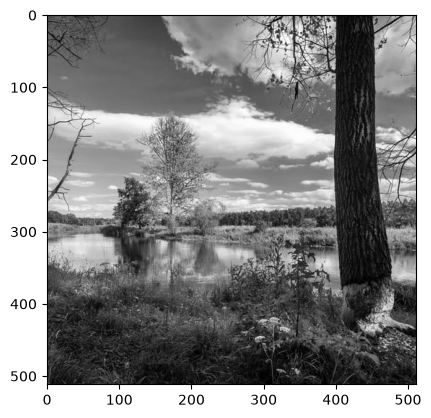

In [17]:
image = cv.imread('img1.jpg')
image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
image = image.astype(np.float64)

plt.imshow(image, cmap="gray")

In [18]:
def haar_transform_horizontal(image_data):
    even_cols = image_data[:, 0::2]
    odd_cols = image_data[:, 1::2]
    low_pass = (even_cols + odd_cols) / 2
    high_pass = (even_cols - odd_cols) / 2
    return np.concatenate([low_pass, high_pass], axis=1)

def haar_wavelet_2d(src):
    horizontal_pass = haar_transform_horizontal(src)
    return haar_transform_horizontal(horizontal_pass.T).T

In [19]:
wavelet_stage1 = haar_wavelet_2d(image)

wavelet_stage2 = wavelet_stage1.copy()
wavelet_stage2[:256, :256] = haar_wavelet_2d(wavelet_stage1[:256, :256])

wavelet_stage3 = wavelet_stage2.copy()
wavelet_stage3[:128, :128] = haar_wavelet_2d(wavelet_stage2[:128, :128])

In [20]:
def normalize(arr):
    arr_min, arr_max = arr.min(), arr.max()
    return np.uint8((arr - arr_min) / (arr_max - arr_min) * 255)

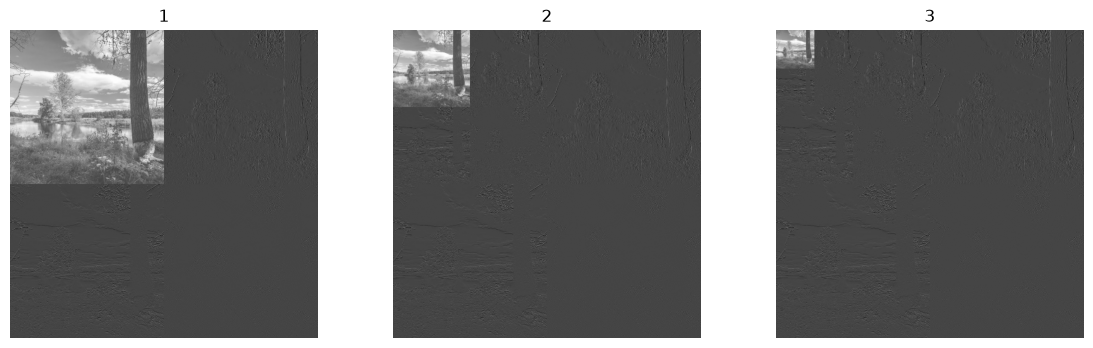

In [21]:
plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(normalize(wavelet_stage1), cmap="gray"), plt.title("1"), plt.axis("off")
plt.subplot(132), plt.imshow(normalize(wavelet_stage2), cmap="gray"), plt.title("2"), plt.axis("off")
plt.subplot(133), plt.imshow(normalize(wavelet_stage3), cmap="gray"), plt.title("3"), plt.axis("off")
plt.show()

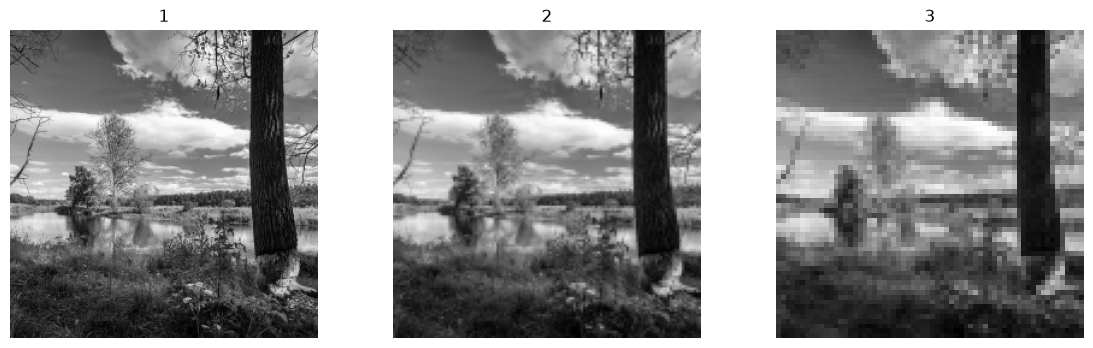

In [23]:
plt.figure(figsize=(14, 4))
plt.subplot(131), plt.imshow(normalize(wavelet_stage1[:256, :256]), cmap="gray"), plt.title("1"), plt.axis("off")
plt.subplot(132), plt.imshow(normalize(wavelet_stage2[:128, :128]), cmap="gray"), plt.title("2"), plt.axis("off")
plt.subplot(133), plt.imshow(normalize(wavelet_stage3[:64, :64]), cmap="gray"), plt.title("3"), plt.axis("off")
plt.show()